In [1]:
%pip install torch_geometric


[notice] A new release of pip is available: 26.0.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [2]:
import os
os.environ["GAT_LLM_MODEL"] = "qwen2.5:14b-instruct"
os.environ["GAT_LLM_BASE_URL"] = "http://localhost:11434/v1"

In [3]:
# ============================================================
# graphrag_gat_pipeline.py
# Подготовка графа GraphRAG и обучение GAT (link prediction)
# ============================================================
import pandas as pd
import torch
import torch.nn.functional as F
from pathlib import Path
from torch_geometric.data import Data
from torch_geometric.utils import coalesce
from sentence_transformers import SentenceTransformer

ARTIFACTS_DIR = Path("./graphrag_preprocessed_rubert/output")
entities = pd.read_parquet(ARTIFACTS_DIR / "entities.parquet")
relationships = pd.read_parquet(ARTIFACTS_DIR / "relationships.parquet")
model = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2")

def make_node_text(row):
    title = str(row.get("title", ""))
    desc = str(row["description"]) if pd.notna(row.get("description")) else ""
    return f"{title}. {desc}"[:512]

node_texts = entities.apply(make_node_text, axis=1).tolist()
embeddings = model.encode(
    node_texts, batch_size=64, show_progress_bar=True,
    convert_to_tensor=True, normalize_embeddings=True,
)

title_to_idx = {}
for idx, title in enumerate(entities["title"].astype(str)):
    if title not in title_to_idx:
        title_to_idx[title] = idx

src = relationships["source"].astype(str).map(title_to_idx)
tgt = relationships["target"].astype(str).map(title_to_idx)
mask = src.notna() & tgt.notna()
src = src[mask].astype(int).values
tgt = tgt[mask].astype(int).values

edge_index = torch.stack([torch.from_numpy(src), torch.from_numpy(tgt)]).long()
edge_index = torch.cat([edge_index, edge_index.flip(0)], dim=1)
edge_index = coalesce(edge_index, num_nodes=len(entities))

data = Data(x=embeddings, edge_index=edge_index, num_nodes=len(entities))
print(data)

Batches: 100%|██████████| 3/3 [00:00<00:00,  5.53it/s]

Data(x=[149, 384], edge_index=[2, 260], num_nodes=149)



/var/folders/gx/8k286hnn4530r9b9hfmfx7080000gn/T/ipykernel_3865/1037939337.py:40: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at /Users/runner/work/pytorch/pytorch/torch/csrc/utils/tensor_numpy.cpp:219.)
  edge_index = torch.stack([torch.from_numpy(src), torch.from_numpy(tgt)]).long()


## Данные для обучения

- `data.edge_index` — список рёбер формы `[2, E]`; для неориентированного графа хранятся оба направления.
- `data.x` — эмбеддинги текстов `title + description`, по одному вектору на узел.
- Число узлов сохраняется, даже если часть узлов не имеет связей.


## Шаг 2. Обучение GAT на GraphRAG-графе

Обучаем **предсказание рёбер**: для пары существующих узлов определяем, есть ли между ними связь.
Целевые метки получаем из структуры графа: 1 — существующее ребро, 0 — выбранная пара без ребра.
Ручные классы узлов для этой задачи не нужны.

Два слоя GAT преобразуют исходные текстовые признаки в эмбеддинги узлов размерности 64.
Первый слой использует 8 голов внимания со скрытой размерностью 32 на голову, второй — одну голову.
Активация — ELU, dropout — 0.6. Декодер оценивает связь по скалярному произведению эмбеддингов.

Рёбра делим примерно на 70% / 15% / 15% для train / validation / test.
Граф для передачи сообщений содержит только train-рёбра на всех этапах.
Обратные направления одной связи остаются в одном разбиении; отрицательные пары также не пересекаются между разбиениями.

Документация: [GATConv](https://pytorch-geometric.readthedocs.io/en/latest/generated/torch_geometric.nn.conv.GATConv.html),
[RandomLinkSplit](https://pytorch-geometric.readthedocs.io/en/latest/generated/torch_geometric.transforms.RandomLinkSplit.html).


### 2.1. Разбиение рёбер и параметры

Сохраняем все узлы, включая изолированные. Петли исключаем из целевых связей: GAT добавляет их внутри свёртки.
Отрицательные пары выбираем из отсутствующих рёбер **полного исходного графа**, чтобы отложенная настоящая связь не получила метку 0.
На один положительный пример берём один отрицательный; выбор фиксируется seed.


In [4]:
import random
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.metrics import average_precision_score, roc_auc_score
from torch_geometric.nn import GATConv
from torch_geometric.transforms import RandomLinkSplit
from torch_geometric.utils import negative_sampling, remove_self_loops, to_undirected

SEED = 42
VAL_RATIO = 0.15
TEST_RATIO = 0.15
MAX_EPOCHS = 300
PATIENCE = 40
LEARNING_RATE = 0.005
WEIGHT_DECAY = 5e-4
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Разбиение выполняется на CPU, независимо от устройства текстового энкодера.
clean_edges, _ = remove_self_loops(data.edge_index.detach().cpu())
graph = Data(
    x=data.x.detach().cpu().float(),
    edge_index=to_undirected(clean_edges, num_nodes=data.num_nodes),
    num_nodes=data.num_nodes,
)
graph.validate(raise_on_error=True)
if not torch.isfinite(graph.x).all():
    raise ValueError("В признаках узлов есть NaN или бесконечные значения.")

num_positive_edges = graph.num_edges // 2
num_val = max(1, int(num_positive_edges * VAL_RATIO))
num_test = max(1, int(num_positive_edges * TEST_RATIO))
if num_positive_edges <= num_val + num_test:
    raise ValueError("Недостаточно рёбер для непустых train/validation/test.")

split_transform = RandomLinkSplit(
    num_val=num_val,
    num_test=num_test,
    is_undirected=True,
    add_negative_train_samples=False,
    neg_sampling_ratio=0.0,
)
train_data, val_data, test_data = split_transform(graph)
splits = [("train", train_data), ("validation", val_data), ("test", test_data)]


negative_edges = negative_sampling(
    edge_index=graph.edge_index,
    num_nodes=graph.num_nodes,
    num_neg_samples=2 * num_positive_edges,
    force_undirected=True,
)
negative_edges = negative_edges[:, negative_edges[0] < negative_edges[1]]
if negative_edges.size(1) < num_positive_edges:
    raise ValueError("В графе недостаточно отсутствующих пар для отрицательных примеров 1:1.")
negative_edges = negative_edges[:, torch.randperm(negative_edges.size(1))]

offset = 0
split_rows = []
for split_name, split in splits:
    positive_edges = split.edge_label_index
    count = positive_edges.size(1)
    selected_negatives = negative_edges[:, offset:offset + count]
    offset += count
    split.edge_label_index = torch.cat([positive_edges, selected_negatives], dim=1)
    split.edge_label = torch.cat([torch.ones(count), torch.zeros(count)])
    split_rows.append({
        "split": split_name,
        "positive": count,
        "negative": count,
    })
    split.to(DEVICE)

message_x = train_data.x
message_edge_index = train_data.edge_index
split_summary = pd.DataFrame(split_rows).set_index("split")
print(f"Устройство: {DEVICE}; узлов: {graph.num_nodes}; связей: {num_positive_edges}")
display(split_summary)


Устройство: cpu; узлов: 149; связей: 130


,positive,negative
split,,
train,92,92
validation,19,19
test,19,19


### 2.2. Двухслойная GAT и декодер связей

На выходе GAT получаем векторы узлов. Для пары (u, v) декодер вычисляет логит связи.
`binary_cross_entropy_with_logits` объединяет sigmoid и бинарную кросс-энтропию;
`log_softmax` из примера классификации узлов здесь заменён декодером рёбер.


In [5]:
class GATForGraphRAG(torch.nn.Module):
    def __init__(
        self, in_channels, hidden_channels=32, out_channels=64,
        heads=8, dropout=0.6,
    ):
        super().__init__()
        self.dropout = dropout
        self.conv1 = GATConv(
            in_channels, hidden_channels, heads=heads, dropout=dropout,
        )
        self.conv2 = GATConv(
            hidden_channels * heads, out_channels,
            heads=1, concat=False, dropout=dropout,
        )
        self.decoder_bias = torch.nn.Parameter(torch.zeros(()))

    def forward(self, x, edge_index):
        x = F.dropout(x, p=self.dropout, training=self.training)
        x = F.elu(self.conv1(x, edge_index))
        x = F.dropout(x, p=self.dropout, training=self.training)
        return self.conv2(x, edge_index)

    def decode(self, z, edge_label_index):
        source, target = edge_label_index
        return (z[source] * z[target]).sum(dim=-1) + self.decoder_bias


model_config = {
    "in_channels": graph.num_node_features,
    "hidden_channels": 32,
    "out_channels": 64,
    "heads": 8,
    "dropout": 0.6,
}
gat_model = GATForGraphRAG(**model_config).to(DEVICE)
optimizer = torch.optim.Adam(
    gat_model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY,
)
print(gat_model)
print(f"Обучаемых параметров: {sum(p.numel() for p in gat_model.parameters()):,}")


GATForGraphRAG(
  (conv1): GATConv(384, 32, heads=8)
  (conv2): GATConv(256, 64, heads=1)
)
Обучаемых параметров: 115,649


### 2.3. Обучение и выбор лучшей эпохи

Оптимизируем BCE на train-парах. После каждой эпохи считаем validation ROC-AUC и
Average Precision (AP); сохраняем веса с максимальной validation AP.
При отсутствии улучшения в течение 40 эпох останавливаем обучение.
Test используется после выбора весов.

ROC-AUC оценивает ранжирование связанных и несвязанных пар; AP — качество выделения положительных связей.
В этой проверке отрицательные и положительные примеры сбалансированы, поэтому ориентир случайного ранжирования — около 0.5.


In [6]:
def ranking_metrics(labels, scores):
    labels = labels.detach().cpu().numpy()
    scores = scores.detach().cpu().numpy()
    return {
        "roc_auc": float(roc_auc_score(labels, scores)),
        "ap": float(average_precision_score(labels, scores)),
    }


@torch.no_grad()
def evaluate_gat(split):
    gat_model.eval()
    z = gat_model(message_x, message_edge_index)
    logits = gat_model.decode(z, split.edge_label_index)
    metrics = ranking_metrics(split.edge_label, logits)
    metrics["loss"] = F.binary_cross_entropy_with_logits(
        logits, split.edge_label,
    ).item()
    return metrics


history = []
best_val_ap = -float("inf")
best_state = None
best_epoch = 0
epochs_without_improvement = 0

for epoch in range(1, MAX_EPOCHS + 1):
    gat_model.train()
    optimizer.zero_grad(set_to_none=True)
    z = gat_model(message_x, message_edge_index)
    train_logits = gat_model.decode(z, train_data.edge_label_index)
    loss = F.binary_cross_entropy_with_logits(train_logits, train_data.edge_label)
    if not torch.isfinite(loss):
        raise RuntimeError(f"На эпохе {epoch} loss перестал быть конечным.")
    loss.backward()
    torch.nn.utils.clip_grad_norm_(gat_model.parameters(), max_norm=1.0)
    optimizer.step()

    val_metrics = evaluate_gat(val_data)
    history.append({
        "epoch": epoch,
        "train_loss": loss.item(),
        "val_loss": val_metrics["loss"],
        "val_roc_auc": val_metrics["roc_auc"],
        "val_ap": val_metrics["ap"],
    })

    if val_metrics["ap"] > best_val_ap + 1e-4:
        best_val_ap = val_metrics["ap"]
        best_epoch = epoch
        best_state = {
            name: tensor.detach().cpu().clone()
            for name, tensor in gat_model.state_dict().items()
        }
        epochs_without_improvement = 0
    else:
        epochs_without_improvement += 1

    if epoch == 1 or epoch % 25 == 0:
        print(
            f"Epoch {epoch:03d} | train BCE={loss.item():.4f} | "
            f"val BCE={val_metrics['loss']:.4f} | "
            f"val ROC-AUC={val_metrics['roc_auc']:.4f} | "
            f"val AP={val_metrics['ap']:.4f}"
        )
    if epochs_without_improvement >= PATIENCE:
        print(f"Ранняя остановка на эпохе {epoch}.")
        break

if best_state is None:
    raise RuntimeError("Не удалось выбрать веса модели: проверьте validation-метрики.")
gat_model.load_state_dict(best_state)
gat_model.eval()
history_df = pd.DataFrame(history)
print(f"Восстановлена эпоха {best_epoch}; лучшая validation AP={best_val_ap:.4f}")


Epoch 001 | train BCE=0.6809 | val BCE=0.6745 | val ROC-AUC=0.8061 | val AP=0.8333
Epoch 025 | train BCE=0.5962 | val BCE=0.6136 | val ROC-AUC=0.8421 | val AP=0.7482
Ранняя остановка на эпохе 41.
Восстановлена эпоха 1; лучшая validation AP=0.8333


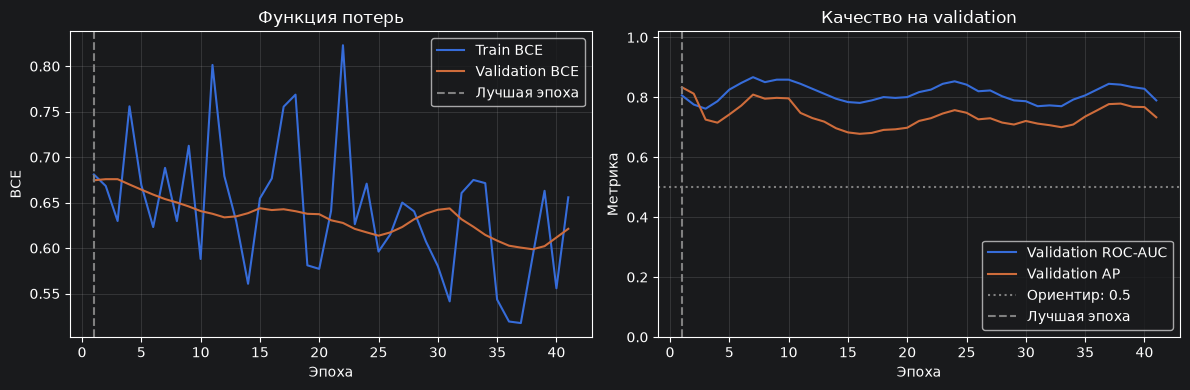

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(history_df["epoch"], history_df["train_loss"], label="Train BCE")
axes[0].plot(history_df["epoch"], history_df["val_loss"], label="Validation BCE")
axes[0].set(title="Функция потерь", xlabel="Эпоха", ylabel="BCE")

axes[1].plot(history_df["epoch"], history_df["val_roc_auc"], label="Validation ROC-AUC")
axes[1].plot(history_df["epoch"], history_df["val_ap"], label="Validation AP")
axes[1].axhline(0.5, color="gray", linestyle=":", label="Ориентир: 0.5")
axes[1].set(title="Качество на validation", xlabel="Эпоха", ylabel="Метрика", ylim=(0, 1.02))
for ax in axes:
    ax.axvline(best_epoch, color="gray", linestyle="--", label="Лучшая эпоха")
    ax.grid(alpha=0.25)
    ax.legend()
fig.tight_layout()
plt.show()


### 2.4. Итоговая оценка

Сравниваем GAT с простым ориентиром: косинусной близостью исходных текстовых эмбеддингов
на **тех же самых** положительных и отрицательных парах.
Проверка восстанавливает связи между существующими узлами GraphRAG.
Для оценки поиска контекста R3 далее понадобятся графы запросов и метрики retrieval.

На небольшом графе результаты зависят от разбиения; высокая validation-метрика сама по себе не гарантирует высокий test-результат.


In [8]:
@torch.no_grad()
def evaluate_text_baseline(split):
    source, target = split.edge_label_index.detach().cpu()
    scores = F.cosine_similarity(graph.x[source], graph.x[target], dim=-1)
    return ranking_metrics(split.edge_label, scores)


val_metrics = evaluate_gat(val_data)
test_metrics = evaluate_gat(test_data)
metric_rows = []
for split_name, split, gat_metrics in [
    ("validation", val_data, val_metrics),
    ("test", test_data, test_metrics),
]:
    for model_name, metrics in [
        ("Text cosine", evaluate_text_baseline(split)),
        ("GAT", gat_metrics),
    ]:
        metric_rows.append({
            "split": split_name,
            "model": model_name,
            "ROC-AUC": metrics["roc_auc"],
            "AP": metrics["ap"],
        })

metrics_df = pd.DataFrame(metric_rows)
display(metrics_df.round(4))

with torch.no_grad():
    gat_node_embeddings = gat_model(message_x, message_edge_index).cpu()
print(f"Эмбеддинги узлов GAT: {tuple(gat_node_embeddings.shape)}")


,split,model,ROC-AUC,AP
0,validation,Text cosine,0.9224,0.9426
1,validation,GAT,0.8061,0.8333
2,test,Text cosine,0.8615,0.9020
3,test,GAT,0.8560,0.8627


Эмбеддинги узлов GAT: (149, 64)


### 2.5. Сохранение результата

Сохраняем лучшие веса, параметры, порядок узлов, признаки, разбиение пар и эмбеддинги,
а также историю обучения и таблицу метрик. Эмбеддинги вычислены на train-графе, использованном при оценке.
Каталог результатов: `gat_link_prediction` рядом с каталогом `output`.


In [9]:
GAT_OUTPUT_DIR = ARTIFACTS_DIR.parent / "gat_link_prediction"
GAT_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
checkpoint_path = GAT_OUTPUT_DIR / "gat_link_prediction.pt"

torch.save({
    "model_state_dict": best_state,
    "model_config": model_config,
    "training_config": {
        "seed": SEED,
        "val_ratio": VAL_RATIO,
        "test_ratio": TEST_RATIO,
        "max_epochs": MAX_EPOCHS,
        "patience": PATIENCE,
        "learning_rate": LEARNING_RATE,
        "weight_decay": WEIGHT_DECAY,
        "best_epoch": best_epoch,
    },
    "text_encoder": "sentence-transformers/all-MiniLM-L6-v2",
    "node_titles": entities["title"].astype(str).tolist(),
    "node_features": graph.x,
    "node_embeddings": gat_node_embeddings,
    "message_edge_index": message_edge_index.detach().cpu(),
    "splits": {
        split_name: {
            "edge_label_index": split.edge_label_index.detach().cpu(),
            "edge_label": split.edge_label.detach().cpu(),
        }
        for split_name, split in splits
    },
    "validation_metrics": val_metrics,
    "test_metrics": test_metrics,
}, checkpoint_path)
history_df.to_csv(GAT_OUTPUT_DIR / "training_history.csv", index=False)
metrics_df.to_csv(GAT_OUTPUT_DIR / "metrics.csv", index=False)
print(f"Модель и эмбеддинги: {checkpoint_path.resolve()}")


Модель и эмбеддинги: /Users/alisaegorova/PycharmProjects/Graphs&GraphModels/graph_preprocess/graphrag_preprocessed_rubert/gat_link_prediction/gat_link_prediction.pt


## Шаг 3. Интеграция GAT в GraphRAG-поток

Поток: **вопрос → граф запроса → GAT → cosine top-k → k-hop подграф → контекст → LLM**.

1. Локальная LLM из настроек GraphRAG выделяет сущности и связи, упомянутые в вопросе.
2. Тексты узлов кодируются тем же MiniLM, что использовался при обучении GAT: `title + description`, до 512 символов.
3. Обученная GAT кодирует граф запроса; косинусное сходство её выходных векторов с GAT-векторами узлов базы определяет кандидатов.
4. Вокруг кандидатов извлекается k-hop окрестность исходного GraphRAG-графа. Связи и описания превращаются в текстовый контекст с идентификаторами источников.
5. LLM отвечает по этому контексту и перечисляет источники.

Шаг выполняется после шага 2. Веса загружаются из сохранённого checkpoint.
Для рабочего поиска пересчитываем GAT-векторы **на полном известном графе**; результаты test из шага 2 по-прежнему относятся к его train-графу.
Оценка retrieval по вопросам потребует отдельного набора вопросов и эталонных контекстов.

Документация: [k_hop_subgraph](https://pytorch-geometric.readthedocs.io/en/latest/modules/utils.html#torch_geometric.utils.k_hop_subgraph),
[LM Studio Chat Completions](https://lmstudio.ai/docs/developer/openai-compat/chat-completions),
[Structured Output](https://lmstudio.ai/docs/developer/openai-compat/structured-output).


### 3.1. Индекс GAT и подключение LLM

Используем отдельный экземпляр GAT с лучшими сохранёнными весами.
Проверяем соответствие порядка узлов checkpoint и текущей таблицы.
Текстовый энкодер остаётся тем же, что в шаге 1; настройки embedding-модели GraphRAG здесь не меняют признаки GAT.

Адрес и имя LLM читаются из `graphrag_preprocessed_rubert/settings.yaml`.
Их можно переопределить переменными окружения `GAT_LLM_BASE_URL`, `GAT_LLM_MODEL`, `GAT_LLM_API_KEY`.
Для текущих настроек нужен запущенный сервер LM Studio с Qwen.


In [10]:
import json
import os
import re
import requests
import yaml
from IPython.display import Markdown
from torch_geometric.utils import k_hop_subgraph

retrieval_checkpoint_path = ARTIFACTS_DIR.parent / "gat_link_prediction" / "gat_link_prediction.pt"
retrieval_checkpoint = torch.load(
    retrieval_checkpoint_path, map_location="cpu", weights_only=True,
)
kb_entities = entities.reset_index(drop=True).copy()
if retrieval_checkpoint["node_titles"] != kb_entities["title"].astype(str).tolist():
    raise ValueError("Порядок сущностей отличается от checkpoint. Повторите подготовку и обучение.")

retrieval_gat = GATForGraphRAG(**retrieval_checkpoint["model_config"]).to(DEVICE)
retrieval_gat.load_state_dict(retrieval_checkpoint["model_state_dict"])
retrieval_gat.eval()
query_text_encoder = model  # SentenceTransformer из шага 1
if query_text_encoder.get_embedding_dimension() != retrieval_checkpoint["model_config"]["in_channels"]:
    raise ValueError("Размерность текстового энкодера отличается от входа обученной GAT.")

kb_features = retrieval_checkpoint["node_features"].to(DEVICE)
kb_edge_index = graph.edge_index.detach().cpu()
with torch.inference_mode():
    kb_gat_embeddings = F.normalize(
        retrieval_gat(kb_features, kb_edge_index.to(DEVICE)), p=2, dim=-1,
    ).cpu()

# Тот же способ сопоставления title -> номер узла, что в подготовке графа.
kb_title_to_idx = {}
for node_idx, title in enumerate(kb_entities["title"].astype(str)):
    kb_title_to_idx.setdefault(title, node_idx)
kb_relationships = relationships.reset_index(drop=True).copy()
kb_relationships["source_idx"] = kb_relationships["source"].astype(str).map(kb_title_to_idx)
kb_relationships["target_idx"] = kb_relationships["target"].astype(str).map(kb_title_to_idx)
kb_relationships["source_id"] = [f"R{i:04d}" for i in range(len(kb_relationships))]

settings_path = ARTIFACTS_DIR.parent / "settings.yaml"
settings = yaml.safe_load(settings_path.read_text(encoding="utf-8"))
completion_settings = settings["completion_models"]["default_completion_model"]
LLM_BASE_URL = os.getenv("GAT_LLM_BASE_URL", completion_settings["api_base"]).rstrip("/")
LLM_MODEL = os.getenv("GAT_LLM_MODEL", completion_settings["model"])
configured_key = str(completion_settings.get("api_key", "local"))
if configured_key.startswith("${") and configured_key.endswith("}"):
    configured_key = os.getenv(configured_key[2:-1], "")
LLM_API_KEY = os.getenv("GAT_LLM_API_KEY", configured_key)


def call_local_llm(messages, *, max_tokens=1500, schema=None):
    payload = {
        "model": LLM_MODEL,
        "messages": messages,
        "temperature": 0,
        "max_tokens": max_tokens,
        "stream": False,
    }
    if schema is not None:
        payload["response_format"] = {
            "type": "json_schema",
            "json_schema": {"name": "graph_rag_result", "strict": True, "schema": schema},
        }
    headers = {"Authorization": f"Bearer {LLM_API_KEY}"} if LLM_API_KEY else {}
    try:
        response = requests.post(
            f"{LLM_BASE_URL}/chat/completions",
            headers=headers, json=payload, timeout=(5, 300),
        )
        response.raise_for_status()
    except requests.RequestException as exc:
        raise RuntimeError(
            f"Ошибка обращения к LLM {LLM_MODEL} по {LLM_BASE_URL}. "
            "Проверьте, что Ollama запущен: ollama list"
        ) from exc
    completion = response.json()
    choice = completion["choices"][0]
    if choice.get("finish_reason") == "length":
        # Не падаем — возвращаем обрезанное, верхний уровень разберётся
        content = choice["message"].get("content", "")
        print(f"[warn] LLM обрезана по max_tokens={max_tokens}, длина={len(content)}")
        if schema is not None:
            try:
                return json.loads(content)
            except json.JSONDecodeError:
                return {}
        return content
    content = choice["message"].get("content")
    if not isinstance(content, str) or not content.strip():
        raise RuntimeError("LLM вернула пустой ответ.")
    return json.loads(content) if schema is not None else content

print(f"Индекс: {tuple(kb_gat_embeddings.shape)}; полных связей: {kb_edge_index.size(1) // 2}")
print(f"LLM: {LLM_MODEL}; адрес: {LLM_BASE_URL}")

# Вторая проекция той же GAT для отладки структурного сглаживания в шаге 4.
with torch.inference_mode():
    kb_gat_self_embeddings = F.normalize(
        retrieval_gat(
            kb_features, torch.empty((2, 0), dtype=torch.long, device=kb_features.device),
        ), p=2, dim=-1,
    ).cpu()


Индекс: (149, 64); полных связей: 130
LLM: qwen2.5:14b-instruct; адрес: http://localhost:11434/v1


### 3.2. Граф вопроса

LLM получает только вопрос и возвращает JSON: узлы с `title` и `description`, связи между локальными id.
Описания не должны содержать ответ или факты, отсутствующие в вопросе.
Связи делаем неориентированными, как при обучении.
Для вопроса без выделенных сущностей используем один узел с текстом вопроса; петли добавит GAT.

Аргумент `query_spec` позволяет передать вручную подготовленный граф для воспроизводимых проверок.
В обычном вызове граф извлекается LLM.


In [14]:
QUERY_GRAPH_SCHEMA = {
    "type": "object",
    "properties": {
        "nodes": {
            "type": "array",
            "items": {
                "type": "object",
                "properties": {
                    "id": {"type": "string"},
                    "title": {"type": "string"},
                    "description": {"type": "string"},
                },
                "required": ["id", "title", "description"],
                "additionalProperties": False,
            },
        },
        "edges": {
            "type": "array",
            "items": {
                "type": "object",
                "properties": {
                    "source": {"type": "string"},
                    "target": {"type": "string"},
                },
                "required": ["source", "target"],
                "additionalProperties": False,
            },
        },
    },
    "required": ["nodes", "edges"],
    "additionalProperties": False,
}


def extract_query_spec(question):
    return call_local_llm([
        {
            "role": "system",
            "content": (
                "Ты извлекаешь граф вопроса. Верни ТОЛЬКО JSON по схеме, без пояснений и markdown.\n"
                "Правила:\n"
                "- До 5 сущностей, явно упомянутых в вопросе. Не додумывай.\n"
                "- id: q0, q1, ...; title: как в вопросе.\n"
                "- description: ОДНО короткое предложение на английском (до 15 слов). Никогда не null.\n"
                "- Рёбра только между существующими id. Если связей не видно — пустой список edges.\n"
                "- Не отвечай на вопрос. Не добавляй факты, которых нет в вопросе."
            ),
        },
        {"role": "user", "content": question},
    ], max_tokens=2000, schema=QUERY_GRAPH_SCHEMA)

def build_query_graph(question, query_spec=None):
    if not isinstance(question, str) or not question.strip():
        raise ValueError("Вопрос должен быть непустой строкой.")
    spec = extract_query_spec(question) if query_spec is None else query_spec
    if not isinstance(spec, dict) or not isinstance(spec.get("nodes"), list) or not isinstance(spec.get("edges"), list):
        raise ValueError("Граф запроса должен содержать списки nodes и edges.")

    # 1) Обрезаем лишние узлы вместо падения
    raw_nodes = spec["nodes"]
    if len(raw_nodes) > 8:
        print(f"[warn] LLM вернула {len(raw_nodes)} узлов, обрезаем до 8")
        raw_nodes = raw_nodes[:8]

    # 2) Фильтруем битые узлы, сохраняя исходный порядок
    local_ids, valid_nodes = {}, []
    for node in raw_nodes:
        if not isinstance(node, dict):
            continue
        node_id = str(node.get("id", "")).strip()
        title = str(node.get("title", "")).strip()
        desc_raw = node.get("description")
        desc = str(desc_raw).strip() if desc_raw not in (None, "null") else ""
        if not node_id or not title or node_id in local_ids:
            continue
        local_ids[node_id] = len(valid_nodes)
        valid_nodes.append({"id": node_id, "title": title, "description": desc})

    # 3) Fallback: если ни одного валидного узла — единственный узел с текстом вопроса
    if not valid_nodes:
        print("[warn] LLM не вернула валидных узлов, использую текст вопроса как один узел")
        valid_nodes = [{"id": "q0", "title": question.strip(), "description": ""}]
        local_ids = {"q0": 0}

    # 4) Пропускаем рёбра с несуществующими id вместо ValueError
    pairs, skipped = set(), 0
    for edge in spec["edges"]:
        if not isinstance(edge, dict):
            skipped += 1
            continue
        src, tgt = edge.get("source"), edge.get("target")
        if src not in local_ids or tgt not in local_ids:
            skipped += 1
            continue
        s, t = local_ids[src], local_ids[tgt]
        if s != t:
            pairs.add((s, t))
            pairs.add((t, s))
    if skipped:
        print(f"[warn] Пропущено {skipped} рёбер с несуществующими узлами")

    # 5) Fallback: если рёбер не осталось, но узлов > 1 — соединяем в клику
    if not pairs and len(valid_nodes) > 1:
        for i in range(len(valid_nodes)):
            for j in range(len(valid_nodes)):
                if i != j:
                    pairs.add((i, j))
        print(f"[warn] Рёбра не найдены, использую полную связность ({len(valid_nodes)} узлов)")

    query_edges = (
        torch.tensor(sorted(pairs), dtype=torch.long).t().contiguous()
        if pairs else torch.empty((2, 0), dtype=torch.long)
    )
    query_nodes = pd.DataFrame(valid_nodes)
    texts = query_nodes.apply(make_node_text, axis=1).tolist()
    query_x = query_text_encoder.encode(
        texts, convert_to_tensor=True, normalize_embeddings=True, show_progress_bar=False,
    )
    query_data = Data(
        x=query_x.detach().float().to(DEVICE),
        edge_index=query_edges.to(DEVICE),
        num_nodes=len(valid_nodes),
    )
    query_data.validate(raise_on_error=True)
    return query_data, query_nodes, {"nodes": valid_nodes, "edges": spec["edges"]}

### 3.3. GAT-поиск и извлечение контекста

Косинусные оценки считаются **между выходами GAT**. Для узла базы берём максимальное сходство с узлами вопроса.
Это оценки ранжирования, а не вероятности правильного ответа.
Далее `k_hop_subgraph` извлекает окрестность top-k узлов по полному `edge_index`.

Возвращаем полные таблицы найденного подграфа. Для промпта выбираем связи с приоритетом кандидатов
и ограничиваем объём контекста целыми записями. Идентификаторы `R...` обозначают исходные связи,
`E...` — исходные сущности; `text_unit_ids` остаются в таблицах для проверки происхождения фактов.


In [15]:
@torch.inference_mode()
def gat_similarity_scores(query_data, *, pooling="max", self_view_weight=0.0):
    if pooling not in {"max", "mean"}:
        raise ValueError("pooling должен быть max или mean.")
    if not 0 <= self_view_weight < 1:
        raise ValueError("self_view_weight должен быть в диапазоне [0, 1).")
    query_embeddings = F.normalize(
        retrieval_gat(query_data.x, query_data.edge_index), p=2, dim=-1,
    ).cpu()
    kb_embeddings = kb_gat_embeddings
    if self_view_weight > 0:
        query_self_embeddings = F.normalize(
            retrieval_gat(
                query_data.x, torch.empty((2, 0), dtype=torch.long, device=query_data.x.device),
            ), p=2, dim=-1,
        ).cpu()
        query_embeddings = F.normalize(
            (1 - self_view_weight) * query_embeddings + self_view_weight * query_self_embeddings,
            p=2, dim=-1,
        )
        kb_embeddings = F.normalize(
            (1 - self_view_weight) * kb_gat_embeddings + self_view_weight * kb_gat_self_embeddings,
            p=2, dim=-1,
        )
    similarities = query_embeddings @ kb_embeddings.t()
    max_scores, matched_query = similarities.max(dim=0)
    scores = max_scores if pooling == "max" else similarities.mean(dim=0)
    return scores, matched_query, query_embeddings


def serialize_subgraph(context_nodes, context_relationships, *, max_context_chars=10000):
    if max_context_chars < 1000:
        raise ValueError("max_context_chars должен быть не меньше 1000.")
    lines = ["Факты GraphRAG. R — связь, E — описание сущности. Используй указанные id источников."]
    source_records = {}

    def append_record(source_id, payload):
        line = f"[{source_id}] " + json.dumps(payload, ensure_ascii=False)
        if len("\n".join(lines + [line])) <= max_context_chars:
            lines.append(line)
            source_records[source_id] = payload
            return True
        return False

    # Сначала сведения о seed-узлах, затем триплеты, затем остальные описания.
    seeds = context_nodes.loc[context_nodes["is_seed"]]
    other_nodes = context_nodes.loc[~context_nodes["is_seed"]]
    for row in seeds.itertuples():
        append_record(f"E{row.node_idx:04d}", {"title": str(row.title), "description": str(row.description)})
    for row in context_relationships.itertuples():
        append_record(row.source_id, {
            "source": str(row.source),
            "relation": str(row.description),
            "target": str(row.target),
        })
    for row in other_nodes.itertuples():
        append_record(f"E{row.node_idx:04d}", {"title": str(row.title), "description": str(row.description)})
    return "\n".join(lines), source_records


@torch.inference_mode()
def retrieve_with_gat(question, *, top_k=10, num_hops=1, max_context_chars=10000, query_spec=None, query_pooling="max", self_view_weight=0.0):
    if not isinstance(top_k, int) or top_k < 1:
        raise ValueError("top_k должен быть положительным целым числом.")
    if not isinstance(num_hops, int) or num_hops < 0:
        raise ValueError("num_hops должен быть целым числом не меньше 0.")

    query_data, query_nodes, spec = build_query_graph(question, query_spec=query_spec)
    scores, matched_query, query_embeddings = gat_similarity_scores(
        query_data, pooling=query_pooling, self_view_weight=self_view_weight,
    )
    seed_indices = torch.argsort(scores, descending=True, stable=True)[:min(top_k, len(kb_entities))]
    seed_scores = scores[seed_indices]
    candidates = pd.DataFrame({
        "node_idx": seed_indices.tolist(),
        "title": kb_entities.iloc[seed_indices.tolist()]["title"].tolist(),
        "gat_cosine": seed_scores.tolist(),
        "matched_query": query_nodes.iloc[matched_query[seed_indices].tolist()]["title"].tolist(),
    })

    subset, subgraph_edges, _, _ = k_hop_subgraph(
        seed_indices, num_hops, kb_edge_index,
        relabel_nodes=False, num_nodes=len(kb_entities),
    )
    node_set = set(subset.tolist())
    seed_set = set(seed_indices.tolist())
    context_nodes = kb_entities.iloc[subset.tolist()].copy()
    context_nodes["node_idx"] = subset.tolist()
    context_nodes["gat_cosine"] = scores[subset].tolist()
    context_nodes["is_seed"] = context_nodes["node_idx"].isin(seed_set)
    context_nodes = context_nodes.sort_values(
        ["is_seed", "gat_cosine", "node_idx"], ascending=[False, False, True],
    )

    context_relationships = kb_relationships.loc[
        kb_relationships["source_idx"].isin(node_set)
        & kb_relationships["target_idx"].isin(node_set)
        & kb_relationships["source_idx"].ne(kb_relationships["target_idx"])
    ].copy()
    context_relationships["seed_hits"] = (
        context_relationships["source_idx"].isin(seed_set).astype(int)
        + context_relationships["target_idx"].isin(seed_set).astype(int)
    )
    context_relationships = context_relationships.sort_values(
        ["seed_hits", "weight", "source_id"], ascending=[False, False, True],
    )
    context, source_records = serialize_subgraph(
        context_nodes, context_relationships, max_context_chars=max_context_chars,
    )
    stats = {
        "query_nodes": query_data.num_nodes,
        "query_edges": query_data.num_edges // 2,
        "seed_nodes": len(candidates),
        "subgraph_nodes": len(context_nodes),
        "subgraph_relationships": len(context_relationships),
        "serialized_nodes": sum(key.startswith("E") for key in source_records),
        "serialized_relationships": sum(key.startswith("R") for key in source_records),
        "context_chars": len(context),
    }
    return {
        "question": question,
        "top_k": top_k,
        "num_hops": num_hops,
        "query_spec": spec,
        "query_graph": query_data,
        "query_nodes": query_nodes,
        "query_embeddings": query_embeddings,
        "candidates": candidates,
        "context_nodes": context_nodes,
        "context_relationships": context_relationships,
        "subgraph_edge_index": subgraph_edges,
        "context": context,
        "source_records": source_records,
        "stats": stats,
    }


### 3.4. Ответ LLM по контексту

LLM получает вопрос и сериализованный подграф. Инструкция требует отвечать по переданным фактам
и сообщать о недостатке данных. Идентификаторы перечисленных источников проверяем:
ответ с несуществующей ссылкой вызывает ошибку.
Такая проверка контролирует ссылки; фактическую корректность ответа дополнительно проверяют по контексту.


In [12]:
ANSWER_SCHEMA = {
    "type": "object",
    "properties": {
        "answer": {"type": "string"},
        "source_ids": {"type": "array", "items": {"type": "string"}},
        "insufficient_context": {"type": "boolean"},
    },
    "required": ["answer", "source_ids", "insufficient_context"],
    "additionalProperties": False,
}
def answer_from_context(retrieval_result):
    if not retrieval_result["source_records"]:
        return {"answer": "В найденном контексте недостаточно данных для ответа.",
                "source_ids": [], "insufficient_context": True, "citation_warning": None}

    result = call_local_llm([
        {
            "role": "system",
            "content": (
                "Отвечай на русском, ОДНО короткое предложение, максимум 15 слов. "
                "Только факты из CONTEXT. Если ответа нет — напиши 'В контексте нет ответа' "
                "и insufficient_context=true. Не используй знания из памяти. "
                "Для утверждения ставь ОДНУ ссылку [R0000] или [E0000] из CONTEXT. "
                "source_ids — только реальные id из CONTEXT. "
                "Верни ТОЛЬКО JSON, без markdown и пояснений."
            ),
        },
        {
            "role": "user",
            "content": f"Вопрос: {retrieval_result['question']}\n\nCONTEXT:\n{retrieval_result['context']}\nEND_CONTEXT",
        },
    ], max_tokens=1500, schema=ANSWER_SCHEMA)

    cited_ids = set(result.get("source_ids") or [])
    inline_ids = set(re.findall(r"\[([RE]\d{4,})\]", result.get("answer", "")))
    available_ids = set(retrieval_result["source_records"])
    unknown_ids = (cited_ids | inline_ids) - available_ids

    warning = None
    if unknown_ids:
        warning = f"LLM сослалась на отсутствующие источники: {sorted(unknown_ids)}"
    elif not result.get("insufficient_context") and not (cited_ids or inline_ids):
        warning = "LLM дала ответ без ссылок на контекст"

    result["source_ids"] = sorted(cited_ids | inline_ids)
    result["citation_warning"] = warning
    return result


def gat_graphrag_answer(question, **retrieval_kwargs):
    retrieved = retrieve_with_gat(question, **retrieval_kwargs)
    return {"retrieval": retrieved, **answer_from_context(retrieved)}


### 3.5. Пример полного потока

Измените `QUESTION` и заново выполните три следующие ячейки.
`top_k` управляет числом кандидатов, `num_hops` — радиусом окрестности.
Пример делает два вызова локальной LLM: извлечение графа вопроса и ответ по контексту.

В примере берём 10 кандидатов и радиус 1. Более узкий поиск может пропустить нужную связь; параметры следует оценивать на отдельном наборе вопросов.


In [16]:
QUESTION = "В какой организации Скородумов Сергей Валериевич проводил исследование и защищал диссертацию?"

retrieval_result = retrieve_with_gat(
    QUESTION, top_k=5, num_hops=1, max_context_chars=10000,
)
print("Граф вопроса:")
display(retrieval_result["query_nodes"])
print("Кандидаты GAT:")
display(retrieval_result["candidates"].round({"gat_cosine": 4}))
print("Размеры контекста:")
display(pd.DataFrame([retrieval_result["stats"]]))
print(retrieval_result["context"])


Граф вопроса:


,id,title,description
0,q0,Скородумов Сергей Валериевич,Researcher and PhD candidate.
1,q1,organization,Place where research and dissertation were con...


Кандидаты GAT:


,node_idx,title,gat_cosine,matched_query
0,60,РОСНИТИ,0.8076,Скородумов Сергей Валериевич
1,61,МИСИС,0.8012,Скородумов Сергей Валериевич
2,62,ЧЕЛЯБИНСКИЙ МЕТАЛЛУРГИЧЕСКИЙ КОМБИНАТ,0.7803,Скородумов Сергей Валериевич
3,70,М.А. ШТРЕМЕЛЬ,0.7763,Скородумов Сергей Валериевич
4,79,ЧЕЛЯБИНСК,0.7730,Скородумов Сергей Валериевич


Размеры контекста:


,query_nodes,query_edges,seed_nodes,subgraph_nodes,subgraph_relationships,serialized_nodes,serialized_relationships,context_chars
0,2,1,5,8,8,8,8,6368


Факты GraphRAG. R — связь, E — описание сущности. Используй указанные id источников.
[E0060] {"title": "РОСНИТИ", "description": "ROSNITI, which stands for Российский научно-исследовательский институт трубной промышленности (Russian Scientific Research Institute of Tubular Industry), is a prominent institution known for its contributions to the field of tubular industry research. The institute plays a crucial role in advancing scientific knowledge and technological innovations within this sector. Notably, ROSNITI has been involved in the completion of significant academic work, such as dissertations, which are essential for the advancement of research and education in specialized fields.\n\nAdditionally, ROSNITI is also recognized as a printing company that has undertaken the responsibility of printing important scholarly works, including dissertations. This dual role highlights the institute's commitment to both producing high-quality research and disseminating knowledge through effec

In [17]:
answer_result = answer_from_context(retrieval_result)
display(Markdown(answer_result["answer"]))
print("Источники:", ", ".join(answer_result["source_ids"]) or "нет")
print("Недостаточно контекста:", answer_result["insufficient_context"])


РОСНИТИ

Источники: E0060, R0063
Недостаточно контекста: False


In [18]:
RETRIEVAL_OUTPUT_DIR = ARTIFACTS_DIR.parent / "gat_retrieval"
RETRIEVAL_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Индекс полного графа хранится отдельно от эмбеддингов train-графа шага 2.
torch.save({
    "node_titles": kb_entities["title"].astype(str).tolist(),
    "node_embeddings": kb_gat_embeddings,
    "edge_index": kb_edge_index,
    "checkpoint": str(retrieval_checkpoint_path),
    "best_epoch": retrieval_checkpoint["training_config"]["best_epoch"],
}, RETRIEVAL_OUTPUT_DIR / "kb_gat_index.pt")
example = {
    "question": QUESTION,
    "llm_model": LLM_MODEL,
    "top_k": retrieval_result["top_k"],
    "num_hops": retrieval_result["num_hops"],
    "query_graph": retrieval_result["query_spec"],
    "candidates": retrieval_result["candidates"].to_dict(orient="records"),
    "stats": retrieval_result["stats"],
    "context": retrieval_result["context"],
    "source_records": retrieval_result["source_records"],
    **answer_result,
}
(RETRIEVAL_OUTPUT_DIR / "example_result.json").write_text(
    json.dumps(example, ensure_ascii=False, indent=2), encoding="utf-8",
)
(RETRIEVAL_OUTPUT_DIR / "example_answer.md").write_text(
    f"# {QUESTION}\n\n{answer_result['answer']}\n\n"
    f"Источники: {', '.join(answer_result['source_ids'])}\n",
    encoding="utf-8",
)
print(f"Индекс и пример запроса сохранены: {RETRIEVAL_OUTPUT_DIR.resolve()}")


Индекс и пример запроса сохранены: /Users/alisaegorova/PycharmProjects/Graphs&GraphModels/graph_preprocess/graphrag_preprocessed_rubert/gat_retrieval


## Шаг 4. Оценка

In [166]:
import time
import random
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from torch_geometric.data import Data
from torch_geometric.nn import GATConv
from torch_geometric.utils import coalesce, remove_self_loops, to_undirected
from torch_geometric.transforms import RandomLinkSplit
from sklearn.metrics import average_precision_score

class GATForGraphRAG(torch.nn.Module):
    def __init__(self, in_channels, hidden_channels=16, out_channels=64,
                 heads=4, dropout=0.25):
        super().__init__()
        self.dropout = dropout
        self.conv1 = GATConv(in_channels, hidden_channels, heads=heads, dropout=dropout)
        self.ln1 = torch.nn.LayerNorm(hidden_channels * heads)
        self.conv2 = GATConv(hidden_channels * heads, out_channels,
                             heads=1, concat=False, dropout=dropout)
        self.ln2 = torch.nn.LayerNorm(out_channels)
        self.residual = torch.nn.Linear(in_channels, out_channels)
        self.decoder_bias = torch.nn.Parameter(torch.zeros(()))

    def forward(self, x, edge_index):
        x = F.normalize(x, dim=-1)
        h = F.dropout(x, p=self.dropout, training=self.training)
        h = self.ln1(F.elu(self.conv1(h, edge_index)))
        h = F.dropout(h, p=self.dropout, training=self.training)
        h = self.ln2(self.conv2(h, edge_index))
        return F.normalize(h + self.residual(x), dim=-1)

    def decode(self, z, edge_label_index):
        s, t = edge_label_index
        return (z[s] * z[t]).sum(-1) + self.decoder_bias

node_texts = entities.apply(
    lambda r: f"{str(r.get('title', ''))}. "
              f"{str(r['description']) if pd.notna(r.get('description')) else ''}"
              f"[:512]",
    axis=1,
).tolist()

node_embeddings = model.encode(
    node_texts, batch_size=64, show_progress_bar=True,
    convert_to_tensor=True, normalize_embeddings=True,
)

title_to_idx = {}
for idx, title in enumerate(entities["title"].astype(str)):
    title_to_idx.setdefault(title, idx)

src = relationships["source"].astype(str).map(title_to_idx)
tgt = relationships["target"].astype(str).map(title_to_idx)
mask = src.notna() & tgt.notna()
src = src[mask].astype(int).values
tgt = tgt[mask].astype(int).values

edge_index = torch.stack([torch.from_numpy(src), torch.from_numpy(tgt)]).long()
edge_index = coalesce(
    torch.cat([edge_index, edge_index.flip(0)], dim=1),
    num_nodes=len(entities),
)

graph = Data(
    x=node_embeddings.detach().cpu().float(),
    edge_index=to_undirected(
        remove_self_loops(edge_index)[0], num_nodes=len(entities),
    ),
    num_nodes=len(entities),
)
graph.validate(raise_on_error=True)

print(f"graph: nodes={graph.num_nodes}  "
      f"edges={graph.num_edges // 2}  dim={graph.num_node_features}")

SEED = 42
VAL_RATIO = 0.15
TEST_RATIO = 0.15
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

num_pos = graph.num_edges // 2
num_val = max(1, int(num_pos * VAL_RATIO))
num_test = max(1, int(num_pos * TEST_RATIO))
assert num_pos > num_val + num_test

splitter = RandomLinkSplit(
    num_val=num_val, num_test=num_test,
    is_undirected=True,
    add_negative_train_samples=False,
    neg_sampling_ratio=0.0,
)
train_data, val_data, test_data = splitter(graph)
train_data = train_data.to(DEVICE)
val_data = val_data.to(DEVICE)
test_data = test_data.to(DEVICE)

message_x = train_data.x
message_edge_index = train_data.edge_index

@torch.no_grad()
def mine_hard_negatives(x, edge_index, n_per_pos=2, min_cos=0.35, seed=42):
    rng = random.Random(seed)
    x_norm = F.normalize(x, dim=-1)
    sim = (x_norm @ x_norm.T).cpu()
    edge_set = set(map(tuple, edge_index.cpu().t().tolist()))
    forbidden = set(edge_set)
    adj = {}
    for s, t in edge_set:
        adj.setdefault(s, set()).add(t)
    for s, nbrs in adj.items():
        for t in nbrs:
            for w in adj.get(t, set()):
                forbidden.add((s, w))
    ei_cpu = edge_index.cpu()
    neg = []
    for u in ei_cpu[0].unique().tolist():
        nbrs = ei_cpu[1][ei_cpu[0] == u].tolist()
        for v in nbrs:
            sims = sim[v].clone()
            sims[u] = -1
            for nb in nbrs:
                sims[nb] = -1
            topk = sims.topk(min(50, sims.numel())).indices.tolist()
            topk = [w for w in topk if float(sims[w]) >= min_cos and (u, w) not in forbidden]
            rng.shuffle(topk)
            for w in topk[:n_per_pos]:
                neg.append((u, w))
    if not neg:
        raise RuntimeError("hard negatives пусты")
    neg = torch.tensor(neg, dtype=torch.long).t()
    return torch.cat([neg, neg.flip(0)], dim=1).to(edge_index.device)

hard_negatives = mine_hard_negatives(
    graph.x, graph.edge_index, n_per_pos=2, min_cos=0.35, seed=SEED,
)
print(f"hard negatives: {hard_negatives.size(1)}")

perm = torch.randperm(hard_negatives.size(1))
n_pos_tr = train_data.edge_label_index.size(1)
n_pos_va = val_data.edge_label_index.size(1)
n_pos_te = test_data.edge_label_index.size(1)
total_pos = n_pos_tr + n_pos_va + n_pos_te
n_neg_tr = int(hard_negatives.size(1) * n_pos_tr / total_pos)
n_neg_va = int(hard_negatives.size(1) * n_pos_va / total_pos)
n_neg_te = hard_negatives.size(1) - n_neg_tr - n_neg_va

neg_tr = hard_negatives[:, perm[:n_neg_tr]].to(DEVICE)
neg_va = hard_negatives[:, perm[n_neg_tr:n_neg_tr + n_neg_va]].to(DEVICE)
neg_te = hard_negatives[:, perm[n_neg_tr + n_neg_va:]].to(DEVICE)

def attach_negatives(split, neg):
    pos_idx = split.edge_label_index
    n_pos = pos_idx.size(1)
    n_neg = min(neg.size(1), n_pos)
    split.edge_label_index = torch.cat([pos_idx, neg[:, :n_neg]], dim=1)
    split.edge_label = torch.cat([
        torch.ones(n_pos, device=DEVICE),
        torch.zeros(n_neg, device=DEVICE),
    ])
    return split

train_data = attach_negatives(train_data, neg_tr)
val_data = attach_negatives(val_data, neg_va)
test_data = attach_negatives(test_data, neg_te)

print(f"train pairs: {train_data.edge_label_index.size(1)}")
print(f"val pairs:   {val_data.edge_label_index.size(1)}")
print(f"test pairs:  {test_data.edge_label_index.size(1)}")

IN = graph.num_node_features
model_config = dict(in_channels=IN, hidden_channels=16, out_channels=64,
                    heads=4, dropout=0.25)
ARCHITECTURE_NAME = "A_linkpred"

gat_model = GATForGraphRAG(**model_config).to(DEVICE)
optimizer = torch.optim.Adam(gat_model.parameters(), lr=5e-4, weight_decay=1e-3)

print(f"params: {sum(p.numel() for p in gat_model.parameters()):,}")

@torch.no_grad()
def retrieval_recall_at_k(model, x, edge_index, k=5, n_hops=2,
                          n_anchors=30, seed=0):
    model.eval()
    z = F.normalize(model(x, edge_index), dim=-1)
    sim = z @ z.t()
    sim.fill_diagonal_(-1e9)
    adj = {}
    for s, t in edge_index.cpu().t().tolist():
        adj.setdefault(s, set()).add(t)
    def nbrs(node, hops):
        frontier, seen = {node}, {node}
        for _ in range(hops):
            nxt = set()
            for n in frontier:
                nxt.update(adj.get(n, set()))
            nxt -= seen
            seen |= nxt
            frontier = nxt
        return seen - {node}
    rng = random.Random(seed)
    anchors = rng.sample(range(x.size(0)), min(n_anchors, x.size(0)))
    hits, total = 0.0, 0
    for a in anchors:
        gt = nbrs(a, n_hops)
        if not gt:
            continue
        topk = sim[a].topk(k).indices.tolist()
        hits += len(set(topk) & gt) / len(gt)
        total += 1
    return hits / total if total else 0.0

@torch.no_grad()
def evaluate_link(split):
    gat_model.eval()
    z = gat_model(message_x, message_edge_index)
    logits = gat_model.decode(z, split.edge_label_index)
    ap = float(average_precision_score(
        split.edge_label.cpu().numpy(), logits.cpu().numpy(),
    ))
    loss = F.binary_cross_entropy_with_logits(logits, split.edge_label).item()
    return {"ap": ap, "loss": loss}

MAX_EPOCHS = 500
PATIENCE = 15
EVAL_EVERY = 5
ANCHOR_SEEDS = [42, 43, 44]

history = []
best_score = -float("inf")
best_state = None
best_epoch = 0
no_improve = 0

t_start = time.time()
for epoch in range(1, MAX_EPOCHS + 1):
    gat_model.train()
    optimizer.zero_grad(set_to_none=True)
    z = gat_model(message_x, message_edge_index)
    logits = gat_model.decode(z, train_data.edge_label_index)
    loss = F.binary_cross_entropy_with_logits(logits, train_data.edge_label)
    loss.backward()
    torch.nn.utils.clip_grad_norm_(gat_model.parameters(), 1.0)
    optimizer.step()

    if epoch % EVAL_EVERY != 0:
        continue

    val_link = evaluate_link(val_data)
    r5 = float(np.mean([
        retrieval_recall_at_k(
            gat_model, message_x, message_edge_index,
            k=5, n_hops=2, n_anchors=30, seed=s,
        ) for s in ANCHOR_SEEDS
    ]))
    score = val_link["ap"] + r5

    history.append(dict(epoch=epoch, loss=loss.item(),
                        val_ap=val_link["ap"], val_r5=r5, combined=score))

    if score > best_score + 1e-3:
        best_score = score
        best_epoch = epoch
        best_state = {k: v.detach().cpu().clone()
                      for k, v in gat_model.state_dict().items()}
        no_improve = 0
    else:
        no_improve += 1

    if epoch % 25 == 0:
        print(f"epoch {epoch:03d} | loss={loss.item():.3f} | "
              f"ap={val_link['ap']:.3f} | r5={r5:.3f} | score={score:.3f}")

    if no_improve >= PATIENCE // EVAL_EVERY:
        print(f"early stop at {epoch}")
        break

assert best_state is not None
gat_model.load_state_dict(best_state)
gat_model.eval()
history_df = pd.DataFrame(history)

test_link = evaluate_link(test_data)
test_r5 = float(np.mean([
    retrieval_recall_at_k(
        gat_model, message_x, message_edge_index,
        k=5, n_hops=2, n_anchors=30, seed=s,
    ) for s in ANCHOR_SEEDS
]))

print(f"\ntrain time: {time.time() - t_start:.1f}s")
print(f"best epoch: {best_epoch}")
print(f"test AP:    {test_link['ap']:.3f}")
print(f"test R@5:   {test_r5:.3f}")

with torch.inference_mode():
    gat_node_embeddings = gat_model(message_x, message_edge_index).cpu()

norms = gat_node_embeddings.norm(dim=-1)
assert torch.allclose(norms, torch.ones_like(norms), atol=1e-3)

GAT_OUTPUT_DIR = ARTIFACTS_DIR.parent / "gat_link_prediction"
GAT_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
ckpt_path = GAT_OUTPUT_DIR / "gat_link_prediction.pt"

torch.save({
    "model_state_dict": {k: v.detach().cpu().clone()
                         for k, v in gat_model.state_dict().items()},
    "model_config": model_config,
    "architecture": ARCHITECTURE_NAME,
    "training_config": {
        "seed": SEED,
        "best_epoch": best_epoch,
        "learning_rate": 1e-3,
        "weight_decay": 1e-3,
        "hard_negatives": {"n_per_pos": 2, "min_cos": 0.35},
        "max_epochs": MAX_EPOCHS,
        "patience": PATIENCE,
    },
    "text_encoder": "sentence-transformers/all-MiniLM-L6-v2",
    "node_titles": entities["title"].astype(str).tolist(),
    "node_features": graph.x,
    "node_embeddings": gat_node_embeddings,
    "message_edge_index": message_edge_index.detach().cpu(),
    "splits": {
        name: {
            "edge_label_index": split.edge_label_index.detach().cpu(),
            "edge_label": split.edge_label.detach().cpu(),
        }
        for name, split in [("train", train_data),
                            ("validation", val_data),
                            ("test", test_data)]
    },
    "validation_metrics": {"ap": float(history_df["val_ap"].max()),
                           "r5": float(history_df["val_r5"].max())},
    "test_metrics": {"ap": test_link["ap"], "r5": test_r5},
}, ckpt_path)

history_df.to_csv(GAT_OUTPUT_DIR / "training_history.csv", index=False)
print(f"saved: {ckpt_path.resolve()}")

Batches: 100%|██████████| 3/3 [00:00<00:00,  4.11it/s]


graph: nodes=149  edges=130  dim=384
hard negatives: 1036
train pairs: 184
val pairs:   38
test pairs:  38
params: 53,953
epoch 025 | loss=0.522 | ap=0.767 | r5=0.776 | score=1.543
early stop at 25

train time: 0.3s
best epoch: 10
test AP:    0.862
test R@5:   0.771
saved: /Users/alisaegorova/PycharmProjects/Graphs&GraphModels/graph_preprocess/graphrag_preprocessed_rubert/gat_link_prediction/gat_link_prediction.pt


In [151]:
@torch.inference_mode()
def retrieve_with_gat(question, *, top_k=20, max_context_chars=50_000,
                      query_spec=None, **kwargs_ignored):
    query_data, query_nodes, spec = build_query_graph(question, query_spec=query_spec)

    q_emb = F.normalize(
        retrieval_gat(query_data.x, query_data.edge_index), p=2, dim=-1,
    ).cpu()
    sims_matrix = q_emb @ kb_gat_embeddings.t()
    sims = sims_matrix.max(dim=0).values

    top_idx = torch.argsort(sims, descending=True)[:top_k].tolist()

    candidates = pd.DataFrame({
        "node_idx":      top_idx,
        "title":         kb_entities.iloc[top_idx]["title"].tolist(),
        "gat_cosine":    sims[top_idx].tolist(),
        "score":         sims[top_idx].tolist(),
        "matched_query": query_nodes.iloc[
            sims_matrix.argmax(dim=0)[top_idx].tolist()
        ]["title"].tolist(),
    })

    context_nodes = kb_entities.iloc[top_idx].copy().reset_index(drop=True)
    context_nodes["node_idx"]   = top_idx
    context_nodes["gat_cosine"] = sims[top_idx].tolist()
    context_nodes["is_seed"]    = False
    context_nodes.loc[0, "is_seed"] = True

    ctx_set = set(top_idx)
    context_relationships = kb_relationships.loc[
        kb_relationships["source_idx"].isin(ctx_set)
        & kb_relationships["target_idx"].isin(ctx_set)
        & kb_relationships["source_idx"].ne(kb_relationships["target_idx"])
    ].copy()
    context_relationships["seed_hits"] = 0

    context, source_records = serialize_subgraph(
        context_nodes, context_relationships, max_context_chars=max_context_chars,
    )

    return {
        "question":              question,
        "top_k":                 top_k,
        "query_spec":            spec,
        "query_graph":           query_data,
        "query_nodes":           query_nodes,
        "candidates":            candidates,
        "context_nodes":         context_nodes,
        "context_relationships": context_relationships,
        "context":               context,
        "source_records":        source_records,
        "stats": {
            "top_k":         top_k,
            "context_nodes": len(context_nodes),
            "context_chars": len(context),
        },
    }

In [152]:
def answer_from_context(retrieval_result, *, max_tokens=400):
    if not retrieval_result.get("source_records"):
        return {
            "answer": "В контексте нет ответа",
            "source_ids": [],
            "insufficient_context": True,
            "citation_warning": None,
        }

    result = call_local_llm(
        [
            {
                "role": "system",
                "content": (
                    "Ты отвечаешь на вопрос СТРОГО по контексту.\n"
                    "Правила:\n"
                    "1. Ответ — ОДНА короткая сущность или факт, не более 5 слов.\n"
                    "2. Не объясняй, не рассуждай, не цитируй контекст.\n"
                    "3. Только факты из CONTEXT. Не используй знания из памяти.\n"
                    "4. Если в CONTEXT нет прямого ответа — верни ровно "
                    "'В контексте нет ответа' и insufficient_context=true.\n"
                    "5. Не называй сущности, которых нет в CONTEXT.\n"
                    "6. Не пиши общие фразы про тему вопроса ('для улучшения прочности' и т.п.).\n"
                    "7. Ставь ОДНУ ссылку [Rxxxx] или [Exxxx] в конце.\n"
                    "8. Верни ТОЛЬКО JSON по схеме, без markdown."
                ),
            },
            {
                "role": "user",
                "content": (
                    f"Вопрос: {retrieval_result['question']}\n\n"
                    f"CONTEXT:\n{retrieval_result['context']}\nEND_CONTEXT"
                ),
            },
        ],
        max_tokens=max_tokens,
        schema=ANSWER_SCHEMA,
    )

    cited_ids = set(result.get("source_ids") or [])
    inline_ids = set(re.findall(r"\[([RE]\d{4,})\]", result.get("answer", "")))
    available_ids = set(retrieval_result["source_records"])
    unknown_ids = (cited_ids | inline_ids) - available_ids

    warning = None
    if unknown_ids:
        warning = f"LLM сослалась на отсутствующие источники: {sorted(unknown_ids)}"
    elif not result.get("insufficient_context") and not (cited_ids or inline_ids):
        warning = "LLM дала ответ без ссылок"

    result["source_ids"] = sorted(cited_ids | inline_ids)
    result["citation_warning"] = warning
    return result

In [167]:
EVAL_SET_SCIENCE = [
    {
        "question": "Для чего применяется сталь 15Х2НМФА?",
        "type": "entity_lookup", "answer_type": "purpose",
        "gold_node_titles": ["15Х2НМФА"],
        "support_node_titles": [],
        "gold_edges": [],
        "gold_answer_aliases": ["nuclear reactor vessels", "reactor vessel",
                                "корпус", "реактор"],
    },
    {
        "question": "В каком технологическом процессе, помимо атомной энергетики, изучалась сталь 15Х2НМФА?",
        "type": "entity_lookup", "answer_type": "process",
        "gold_node_titles": ["15Х2НМФА"],
        "support_node_titles": [],
        "gold_edges": [],
        "gold_answer_aliases": ["sulfur liquefaction", "liquefaction",
                                "сжижение серы"],
    },
    {
        "question": "Какое содержание серы в стали класса прочности К60?",
        "type": "entity_lookup", "answer_type": "number",
        "gold_node_titles": ["К60"],
        "support_node_titles": [],
        "gold_edges": [],
        "gold_answer_aliases": ["0.003", "0,003", "0.003%"],
    },
    {
        "question": "Для какого вида продукции применяется сталь класса прочности К60?",
        "type": "entity_lookup", "answer_type": "purpose",
        "gold_node_titles": ["К60"],
        "support_node_titles": [],
        "gold_edges": [],
        "gold_answer_aliases": ["gas pipes", "gas pipe", "газовых труб", "газовые трубы"],
    },
    {
        "question": "Для производства какого вида продукции предназначена сталь класса прочности К65?",
        "type": "entity_lookup", "answer_type": "purpose",
        "gold_node_titles": ["К65"],
        "support_node_titles": [],
        "gold_edges": [],
        "gold_answer_aliases": ["gas pipes", "gas pipe", "газовых труб", "газовые трубы"],
    },
    {
        "question": "Какая особенность структуры характерна для стали класса прочности К65?",
        "type": "entity_lookup", "answer_type": "property",
        "gold_node_titles": ["К65"],
        "support_node_titles": [],
        "gold_edges": [],
        "gold_answer_aliases": ["structural heterogeneity", "heterogeneity",
                                "структурная неоднородность", "неоднородность"],
    },
    {
        "question": "Какая термическая обработка применяется к стали 40Х2Н2МА?",
        "type": "entity_lookup", "answer_type": "process",
        "gold_node_titles": ["40Х2Н2МА"],
        "support_node_titles": [],
        "gold_edges": [],
        "gold_answer_aliases": ["high-temperature annealing", "annealing",
                                "tempering", "отпуск", "отжиг"],
    },
    {
        "question": "Какие структуры могут образоваться в стали 40Х2Н2МА после термообработки?",
        "type": "entity_lookup", "answer_type": "structure",
        "gold_node_titles": ["40Х2Н2МА"],
        "support_node_titles": [],
        "gold_edges": [],
        "gold_answer_aliases": ["sorbite", "martensite", "сорбит", "мартенсит"],
    },
    {
        "question": "Каково содержание хрома в стали 15Х2НМФА?",
        "type": "entity_lookup", "answer_type": "number",
        "gold_node_titles": ["СТАЛЬ 15Х2НМФА"],
        "support_node_titles": [],
        "gold_edges": [],
        "gold_answer_aliases": ["15% chromium", "15 % chromium", "15%", "15 %"],
    },
    {
        "question": "Каково содержание никеля в стали 15Х2НМФА?",
        "type": "entity_lookup", "answer_type": "number",
        "gold_node_titles": ["СТАЛЬ 15Х2НМФА"],
        "support_node_titles": [],
        "gold_edges": [],
        "gold_answer_aliases": ["2% nickel", "2 % nickel", "2%", "2 %"],
    },
    {
        "question": "Каково содержание молибдена в стали 15Х2НМФА?",
        "type": "entity_lookup", "answer_type": "number",
        "gold_node_titles": ["СТАЛЬ 15Х2НМФА"],
        "support_node_titles": [],
        "gold_edges": [],
        "gold_answer_aliases": ["0.3% molybdenum", "0.3%", "0,3%"],
    },
]

In [168]:
import re
import time
import numpy as np
import pandas as pd
from collections import Counter

try:
    from unidecode import unidecode
except ImportError:
    import subprocess; subprocess.run(["pip", "install", "-q", "unidecode"])
    from unidecode import unidecode

try:
    from rapidfuzz import fuzz
except ImportError:
    import subprocess; subprocess.run(["pip", "install", "-q", "rapidfuzz"])
    from rapidfuzz import fuzz

def _normalize(text):
    if text is None:
        return ""
    s = str(text).lower().replace("ё", "е")
    s = re.sub(r"[^\w\s]", " ", s)
    return re.sub(r"\s+", " ", s).strip()


def _translit(text):
    return unidecode(_normalize(text)).lower()


def _title_match(a, b, **_):
    """Матч по токенам с транслитерацией (кириллица ↔ латиница)."""
    if not a or not b:
        return False
    sa, sb = _translit(a), _translit(b)
    if not sa or not sb:
        return False
    if sa == sb:
        return True
    ta = {t for t in sa.split() if len(t) >= 3}
    tb = {t for t in sb.split() if len(t) >= 3}
    if ta & tb:
        return True
    if len(sa) >= 4 and sa in sb:
        return True
    if len(sb) >= 4 and sb in sa:
        return True
    try:
        if fuzz.ratio(sa, sb) >= 88:
            return True
    except Exception:
        pass
    return False


_UNCERTAIN = (
    "недостаточно", "не найдено", "не указано", "неизвестно",
    "нет ответа", "нет данных", "в контексте нет",
    "возможно", "вероятно", "предположительно",
)


def _is_garbage_answer(text):
    if not text or len(text.strip()) < 2:
        return True
    if re.search(r"[\u4e00-\u9fff\u3040-\u30ff\uac00-\ud7af]", text):
        return True
    if re.search(r"(true|false|json|schema)", text.lower()):
        return True
    if text.count('"') % 2 != 0:
        return True
    if len(text) > 500:
        return True
    return False


def _matches_any(text, aliases):
    if not text:
        return False
    norm = _normalize(text)
    if any(m in norm for m in _UNCERTAIN):
        return False
    if _is_garbage_answer(text):
        return False
    return any(_title_match(text, a) for a in aliases)


def _resolve(title, kb_title_to_idx):
    """exact → normalized exact → fuzzy (единственный матч)."""
    if not title:
        return None
    if title in kb_title_to_idx:
        return kb_title_to_idx[title]
    t_norm = _normalize(title)
    for kb_title, idx in kb_title_to_idx.items():
        if _normalize(kb_title) == t_norm:
            return idx
    matches = [(kt, i) for kt, i in kb_title_to_idx.items()
               if _title_match(title, kt)]
    if len(matches) == 1:
        return matches[0][1]
    if len(matches) > 1:
        matches.sort(key=lambda x: len(x[0]))
        return matches[0][1]
    return None


def _check_in_text(text, aliases):
    if not text:
        return False, None
    t = _translit(text)
    for a in aliases:
        a_t = _translit(a)
        if len(a_t) >= 3 and a_t in t:
            return True, a
    # fuzzy fallback
    for a in aliases:
        a_t = _translit(a)
        if len(a_t) >= 4:
            try:
                if fuzz.token_set_ratio(a_t, t) >= 90:
                    return True, a
            except Exception:
                pass
    return False, None

def node_hit_at_k(retrieval, gold_ids, k):
    if retrieval is None or not gold_ids:
        return 0.0
    return float(any(i in gold_ids for i in retrieval["candidates"]["node_idx"].tolist()[:k]))


def node_mrr(retrieval, gold_ids):
    if retrieval is None or not gold_ids:
        return 0.0, None
    for rank, idx in enumerate(retrieval["candidates"]["node_idx"].tolist(), 1):
        if idx in gold_ids:
            return 1.0 / rank, rank
    return 0.0, None


def desc_hit_at_k(retrieval, aliases, k):
    """Ответ в description хотя бы одного top-k узла."""
    if retrieval is None:
        return 0.0
    for _, r in retrieval["candidates"].head(k).iterrows():
        desc = str(kb_entities.iloc[r["node_idx"]].get("description", ""))
        found, _ = _check_in_text(desc, aliases)
        if found:
            return 1.0
    return 0.0


def context_hit_at_k(retrieval, item, k, kb_relationships, kb_title_to_idx):
    """Ответ в context: title / description узлов / edge description."""
    if retrieval is None:
        return 0.0
    top_idx = retrieval["candidates"]["node_idx"].tolist()[:k]
    if not top_idx:
        return 0.0
    aliases = item["gold_answer_aliases"]
    top_set = set(top_idx)

    # 1) node titles
    for idx in top_idx:
        if _check_in_text(str(kb_entities.iloc[idx]["title"]), aliases)[0]:
            return 1.0
    # 2) node descriptions
    for idx in top_idx:
        if _check_in_text(str(kb_entities.iloc[idx].get("description", "")), aliases)[0]:
            return 1.0
    # 3) edges between top-k
    for _, e in kb_relationships.iterrows():
        if e["source_idx"] in top_set and e["target_idx"] in top_set:
            if _check_in_text(str(e["description"]), aliases)[0]:
                return 1.0
    # 4) edges from support-seed to top-k
    for st in item.get("support_node_titles", []):
        sidx = _resolve(st, kb_title_to_idx)
        if sidx is None:
            continue
        for _, e in kb_relationships.iterrows():
            if ((e["source_idx"] == sidx and e["target_idx"] in top_set) or
                (e["target_idx"] == sidx and e["source_idx"] in top_set)):
                if _check_in_text(str(e["description"]), aliases)[0]:
                    return 1.0
    return 0.0


def edge_recall_at_k(retrieval, item, k, kb_relationships, kb_title_to_idx):
    if retrieval is None or not item.get("gold_edges"):
        return np.nan
    top_set = set(retrieval["candidates"]["node_idx"].tolist()[:k])
    ok = 0
    for src_t, tgt_t in item["gold_edges"]:
        s = _resolve(src_t, kb_title_to_idx)
        t = _resolve(tgt_t, kb_title_to_idx)
        if s is not None and t is not None and s in top_set and t in top_set:
            ok += 1
    return ok / len(item["gold_edges"])


# ============================================================
# ЧАСТЬ 3 — МЕТРИКИ ОТВЕТА
# ============================================================
def answer_correct_auto(answer_text, item):
    if not answer_text:
        return 0.0
    norm = _normalize(answer_text)
    if any(m in norm for m in _UNCERTAIN):
        return 0.0
    if _is_garbage_answer(answer_text):
        return 0.0
    return float(any(_title_match(answer_text, a) for a in item["gold_answer_aliases"]))


def exact_match(answer_text, aliases):
    if not answer_text:
        return 0.0
    a_norm = _normalize(answer_text)
    return float(any(a_norm == _normalize(alias) for alias in aliases))


def token_f1(answer_text, aliases):
    if not answer_text:
        return 0.0
    pred = _normalize(answer_text).split()
    if not pred:
        return 0.0
    best = 0.0
    for alias in aliases:
        gold = _normalize(alias).split()
        if not gold:
            continue
        overlap = sum((Counter(pred) & Counter(gold)).values())
        if overlap == 0:
            continue
        p = overlap / len(pred)
        r = overlap / len(gold)
        f = 2 * p * r / (p + r) if (p + r) else 0.0
        best = max(best, f)
    return best
EVAL_SET_FINAL = [
    {
        "question": "В какой организации Скородумов Сергей Валериевич проводил исследование и защищал диссертацию?",
        "type": "entity_lookup", "answer_type": "organization",
        "gold_node_titles": ["НИТУ «МИСИС»"],
        "support_node_titles": ["СКОРОДУМОВ СЕРГЕЙ ВАЛЕРИЕВИЧ"],
        "gold_edges": [("СКОРОДУМОВ СЕРГЕЙ ВАЛЕРИЕВИЧ", "НИТУ «МИСИС»")],
        "gold_answer_aliases": ["ниту «мисис»", "ниту мисис", "мисис", "misis"],
    },
    {
        "question": "В каком городе Скородумов защищал диссертацию?",
        "type": "entity_lookup", "answer_type": "city",
        "gold_node_titles": ["МОСКВА"],
        "support_node_titles": ["СКОРОДУМОВ СЕРГЕЙ ВАЛЕРИЕВИЧ"],
        "gold_edges": [("СКОРОДУМОВ СЕРГЕЙ ВАЛЕРИЕВИЧ", "МОСКВА")],
        "gold_answer_aliases": ["москва", "москве", "moscow"],
    },
    {
        "question": "Кто автор диссертации «Сопоставление структуры и вязкости конструкционных сталей»?",
        "type": "entity_lookup", "answer_type": "person",
        "gold_node_titles": ["СКОРОДУМОВ СЕРГЕЙ ВАЛЕРИЕВИЧ"],
        "support_node_titles": [],
        "gold_edges": [],
        "gold_answer_aliases": ["скородумов сергей валериевич", "скородумов"],
    },
    {
        "question": "Кто был научным руководителем диссертации Скородумова Сергея Валериевича?",
        "type": "relational", "answer_type": "person",
        "gold_node_titles": ["А.В. КУДРЯ"],
        "support_node_titles": ["СКОРОДУМОВ СЕРГЕЙ ВАЛЕРИЕВИЧ"],
        "gold_edges": [("СКОРОДУМОВ СЕРГЕЙ ВАЛЕРИЕВИЧ", "А.В. КУДРЯ")],
        "gold_answer_aliases": ["а.в. кудря", "кудря", "kudrya"],
    },
    {
        "question": "Кто был официальным оппонентом от ЦНИИЧЕРМЕТ им. И.П. Бардина?",
        "type": "relational", "answer_type": "person",
        "gold_node_titles": ["Г.А. ФИЛИППОВ"],
        "support_node_titles": ["СКОРОДУМОВ СЕРГЕЙ ВАЛЕРИЕВИЧ", "ЦНИИЧЕРМЕТ ИМ. И.П. БАРДИНА"],
        "gold_edges": [("СКОРОДУМОВ СЕРГЕЙ ВАЛЕРИЕВИЧ", "Г.А. ФИЛИППОВ")],
        "gold_answer_aliases": ["г.а. филиппов", "филиппов", "filippov"],
    },
    {
        "question": "Кто был официальным оппонентом от ИМЕТ РАН им. А.А. Байкова?",
        "type": "relational", "answer_type": "person",
        "gold_node_titles": ["М.М. КАНТОР"],
        "support_node_titles": ["СКОРОДУМОВ СЕРГЕЙ ВАЛЕРИЕВИЧ", "ИМЕТ РАН ИМ. А.А. БАЙКОВА"],
        "gold_edges": [("СКОРОДУМОВ СЕРГЕЙ ВАЛЕРИЕВИЧ", "М.М. КАНТОР")],
        "gold_answer_aliases": ["м.м. кантор", "кантор", "kantor"],
    },
    {
        "question": "На заседании какого диссертационного совета защищалась работа?",
        "type": "entity_lookup", "answer_type": "code",
        "gold_node_titles": ["ДИССЕРТАЦИОННЫЙ СОВЕТ Д.212.132.08"],
        "support_node_titles": ["СКОРОДУМОВ СЕРГЕЙ ВАЛЕРИЕВИЧ"],
        "gold_edges": [("СКОРОДУМОВ СЕРГЕЙ ВАЛЕРИЕВИЧ", "ДИССЕРТАЦИОННЫЙ СОВЕТ Д.212.132.08")],
        "gold_answer_aliases": ["д.212.132.08", "д 212.132.08", "212.132.08"],
    },
    {
        "question": "Кто был ученым секретарем диссертационного совета, где защищался Скородумов?",
        "type": "relational", "answer_type": "person",
        "gold_node_titles": ["С.И. МУХИН"],
        "support_node_titles": ["ДИССЕРТАЦИОННЫЙ СОВЕТ Д.212.132.08", "СКОРОДУМОВ СЕРГЕЙ ВАЛЕРИЕВИЧ"],
        "gold_edges": [("СКОРОДУМОВ СЕРГЕЙ ВАЛЕРИЕВИЧ", "С.И. МУХИН")],
        "gold_answer_aliases": ["с.и. мухин", "с.и.мухин", "мухин", "muhin"],
    },
    {
        "question": "По какому адресу проходила защита диссертации?",
        "type": "entity_lookup", "answer_type": "address",
        "gold_node_titles": ["МОСКВА"],
        "support_node_titles": ["СКОРОДУМОВ СЕРГЕЙ ВАЛЕРИЕВИЧ"],
        "gold_edges": [],
        "gold_answer_aliases": ["119049", "ленинский проспект", "аудитория б 607", "москва ленинский"],
    },
    {
        "question": "Какая сталь исследовалась для корпусов атомных реакторов?",
        "type": "entity_lookup", "answer_type": "steel",
        "gold_node_titles": ["15Х2НМФА"],
        "support_node_titles": [],
        "gold_edges": [],
        "gold_answer_aliases": ["15х2нмфа", "15x2nmfa"],
    },
    {
        "question": "Для какого магистрального газопровода предназначены трубы К65?",
        "type": "entity_lookup", "answer_type": "project",
        "gold_node_titles": ["БОВАНЕНКОВО-УХТА"],
        "support_node_titles": [],
        "gold_edges": [],
        "gold_answer_aliases": ["бованенково-ухта", "bovanenkovo-uhta", "bovanenkovo"],
    },
    {
        "question": "При каком вузе действовал диссертационный совет, где защищался Скородумов?",
        "type": "entity_lookup", "answer_type": "organization",
        "gold_node_titles": ["НИТУ «МИСИС»"],
        "support_node_titles": ["ДИССЕРТАЦИОННЫЙ СОВЕТ Д.212.132.08"],
        "gold_edges": [],
        "gold_answer_aliases": ["ниту «мисис»", "ниту мисис", "мисис", "misis"],
    },
    {
        "question": "В какой организации выполнялась диссертационная работа Скородумова?",
        "type": "entity_lookup", "answer_type": "organization",
        "gold_node_titles": ["РОСНИТИ"],
        "support_node_titles": ["СКОРОДУМОВ СЕРГЕЙ ВАЛЕРИЕВИЧ"],
        "gold_edges": [("РОСНИТИ", "НИТУ «МИСИС»")],
        "gold_answer_aliases": ["роснити", "rosniti",
                                "российский научно-исследовательский институт трубной промышленности"],
    },
    {
        "question": "В каком городе находится РОСНИТИ?",
        "type": "entity_lookup", "answer_type": "city",
        "gold_node_titles": ["ЧЕЛЯБИНСК"],
        "support_node_titles": ["РОСНИТИ"],
        "gold_edges": [("РОСНИТИ", "ЧЕЛЯБИНСК")],
        "gold_answer_aliases": ["челябинск", "chelyabinsk"],
    },
    {
        "question": "Кто был научным руководителем диссертации Струина Алексея Олеговича?",
        "type": "relational", "answer_type": "person",
        "gold_node_titles": ["ПЫШМИНЦЕВ ИГОРЬ ЮРЬЕВИЧ"],
        "support_node_titles": ["СТРУИН АЛЕКСЕЙ ОЛЕГОВИЧ"],
        "gold_edges": [("ПЫШМИНЦЕВ ИГОРЬ ЮРЬЕВИЧ", "СТРУИН АЛЕКСЕЙ ОЛЕГОВИЧ")],
        "gold_answer_aliases": ["пышминцев", "пышминцев игорь юрьевич", "pyshmincev"],
    },
    {
        "question": "Кто был официальным оппонентом диссертации Струина Алексея Олеговича?",
        "type": "relational", "answer_type": "person",
        "gold_node_titles": ["НАСТИЧ С.Ю.", "САЗОНОВ Ю.Б."],
        "support_node_titles": ["СТРУИН АЛЕКСЕЙ ОЛЕГОВИЧ"],
        "gold_edges": [("НАСТИЧ С.Ю.", "СТРУИН АЛЕКСЕЙ ОЛЕГОВИЧ"),
                       ("САЗОНОВ Ю.Б.", "СТРУИН АЛЕКСЕЙ ОЛЕГОВИЧ")],
        "gold_answer_aliases": ["настич с.ю.", "настич", "nastich",
                                "сазонов ю.б.", "сазонов", "sazonov"],
    },
]

print(f"EVAL_SET_FINAL: {len(EVAL_SET_FINAL)}")
print(f"  entity_lookup: {sum(1 for x in EVAL_SET_FINAL if x['type'] == 'entity_lookup')}")
print(f"  relational:    {sum(1 for x in EVAL_SET_FINAL if x['type'] == 'relational')}")
for eval_data in [EVAL_SET_FINAL, EVAL_SET_SCIENCE]:
    print("DATASET")
    print("=" * 80)
    print("VALIDATION DATASET")
    print("=" * 80)
    valid_items = []
    for i, item in enumerate(eval_data, 1):
        ids = [_resolve(t, kb_title_to_idx) for t in item["gold_node_titles"]]
        if any(x is None for x in ids):
            print(f"  ⚠️  [{i:02d}] SKIP — gold не резолвится: {item['gold_node_titles']}")
            continue
        valid_items.append(item)
        print(f"  ✓ [{i:02d}] {item['type']:14s} {item['question'][:55]}")

    print(f"\nВалидных: {len(valid_items)}/{len(eval_data)}")


    TOP_K = 20
    MAX_CTX = 50_000

    print("\n" + "=" * 80)
    print(f"RUN (n={len(valid_items)}, top_k={TOP_K})")
    print("=" * 80)

    rows, all_retrievals, all_answers = [], [], []
    t_start = time.time()

    for i, item in enumerate(valid_items, start=1):
        t0 = time.time()

        # --- retrieval ---
        try:
            ret = retrieve_with_gat(item["question"], top_k=TOP_K,
                                    max_context_chars=MAX_CTX)
            ret_err = None
        except Exception as e:
            ret, ret_err = None, f"{type(e).__name__}: {e}"

        # --- answer ---
        try:
            ans = answer_from_context(ret) if ret else \
                  {"answer": "", "source_ids": [], "insufficient_context": True}
            ans_err = None
        except Exception as e:
            ans = {"answer": "", "source_ids": [], "insufficient_context": True}
            ans_err = f"{type(e).__name__}: {e}"

        gold_ids = {_resolve(t, kb_title_to_idx) for t in item["gold_node_titles"]}
        gold_ids = {x for x in gold_ids if x is not None}

        mrr, first_rank = node_mrr(ret, gold_ids)
        row = {
            "n": i,
            "type": item["type"],
            "answer_type": item["answer_type"],
            "question": item["question"][:60],

            "node_hit@1":  node_hit_at_k(ret, gold_ids, 1),
            "node_hit@5":  node_hit_at_k(ret, gold_ids, 5),
            "node_hit@10": node_hit_at_k(ret, gold_ids, 10),
            "node_hit@20": node_hit_at_k(ret, gold_ids, 20),
            "mrr":         mrr,
            "first_rank":  first_rank,
            "desc_hit@5":  desc_hit_at_k(ret, item["gold_answer_aliases"], 5),
            "desc_hit@10": desc_hit_at_k(ret, item["gold_answer_aliases"], 10),
            "desc_hit@20": desc_hit_at_k(ret, item["gold_answer_aliases"], 20),
            "ctx_hit@5":   context_hit_at_k(ret, item, 5, kb_relationships, kb_title_to_idx),
            "ctx_hit@10":  context_hit_at_k(ret, item, 10, kb_relationships, kb_title_to_idx),
            "ctx_hit@20":  context_hit_at_k(ret, item, 20, kb_relationships, kb_title_to_idx),
            "edge_recall@20": edge_recall_at_k(ret, item, 20, kb_relationships, kb_title_to_idx),

            "answer":            ans.get("answer", ""),
            "insufficient":      bool(ans.get("insufficient_context", True)),
            "source_ids":        "; ".join(ans.get("source_ids", [])),
            "answer_correct":    answer_correct_auto(ans.get("answer", ""), item),
            "exact_match":       exact_match(ans.get("answer", ""), item["gold_answer_aliases"]),
            "token_f1":          token_f1(ans.get("answer", ""), item["gold_answer_aliases"]),

            "context_chars": ret["stats"]["context_chars"] if ret else 0,
            "retrieval_error": ret_err,
            "answer_error":    ans_err,
            "elapsed_sec":     round(time.time() - t0, 1),
        }
        rows.append(row)
        all_retrievals.append(ret)
        all_answers.append(ans)

        print(f"[{i:02d}/{len(valid_items)}] {item['type']:10s}  "
              f"node@20={row['node_hit@20']:.0f}  ctx@20={row['ctx_hit@20']:.0f}  "
              f"ans={row['answer_correct']:.0f}  ({row['elapsed_sec']}s)  "
              f"{item['question'][:40]}")

    print(f"\n[done] {time.time()-t_start:.1f}s")

    eval_df = pd.DataFrame(rows)


    def _m(col, df=None):
        df = df if df is not None else eval_df
        return df[col].mean() if col in df.columns else np.nan


    print("\n" + "=" * 80)
    print("PER-QUESTION")
    print("=" * 80)
    show_cols = ["n", "type", "node_hit@5", "node_hit@10", "node_hit@20",
                 "mrr", "desc_hit@10", "ctx_hit@10", "ctx_hit@20",
                 "edge_recall@20", "answer_correct", "exact_match", "token_f1"]
    display(eval_df[[c for c in show_cols if c in eval_df.columns]].round(3))

    print("\n" + "=" * 80)
    print("RETRIEVAL — PROGRESSION")
    print("=" * 80)
    retr_metrics = [
        "node_hit@1", "node_hit@5", "node_hit@10", "node_hit@20",
        "desc_hit@5", "desc_hit@10", "desc_hit@20",
        "ctx_hit@5", "ctx_hit@10", "ctx_hit@20",
        "mrr", "edge_recall@20",
    ]
    print(f"  {'metric':<18} {'overall':<10} {'entity':<10} {'relational':<12}")
    for col in retr_metrics:
        if col not in eval_df.columns:
            continue
        overall = eval_df[col].mean()
        ent = eval_df[eval_df["type"] == "entity_lookup"][col].mean()
        rel = eval_df[eval_df["type"] == "relational"][col].mean()
        def fmt(v):
            return f"{v:.3f}" if not np.isnan(v) else "  —  "
        print(f"  {col:<18} {fmt(overall):<10} {fmt(ent):<10} {fmt(rel):<12}")

    print("\n" + "=" * 80)
    print("ANSWER METRICS")
    print("=" * 80)
    for col in ["answer_correct", "exact_match", "token_f1"]:
        overall = eval_df[col].mean()
        ent = eval_df[eval_df["type"] == "entity_lookup"][col].mean()
        rel = eval_df[eval_df["type"] == "relational"][col].mean()
        print(f"  {col:<18} {overall:<10.3f} {ent:<10.3f} {rel:<12.3f}")

    print("\n" + "=" * 80)
    print("HEALTH")
    print("=" * 80)
    print(f"  retrieval errors : {eval_df['retrieval_error'].notna().sum()}/{len(eval_df)}")
    print(f"  answer errors    : {eval_df['answer_error'].notna().sum()}/{len(eval_df)}")
    print(f"  insufficient     : {int(eval_df['insufficient'].sum())}/{len(eval_df)}")
    print(f"  mean ctx_chars   : {eval_df['context_chars'].mean():.0f}")

    print("\n" + "=" * 80)
    print("R9 CHECK  (≥60% правильных)")
    print("=" * 80)
    n_ok = int(eval_df["answer_correct"].sum())
    n_all = len(eval_df)
    rate = n_ok / n_all
    print(f"  answer_correct = {n_ok}/{n_all} = {100*rate:.0f}%")
    print(f"  → {'✅ R9 PASSED' if rate >= 0.60 else '⚠️  BELOW 60%'}")

    # согласованность retrieval ↔ answer
    corr = eval_df[["ctx_hit@20", "answer_correct"]].corr().iloc[0, 1]
    print(f"\n  corr(ctx_hit@20, answer_correct) = {corr:.3f}")
    print(f"  {'✅ context_hit@20 предсказывает answer' if corr >= 0.50 else '⚠️ метрики рассогласованы'}")

    print("\n" + "=" * 80)
    print("FAIL CASES (answer_correct = 0)")
    print("=" * 80)
    fails = eval_df[eval_df["answer_correct"] == 0]
    if len(fails) == 0:
        print("✓ все ответы верны")
    else:
        for _, r in fails.iterrows():
            print(f"\n[{r['n']:02d}] [{r['type']}] {r['question']}")
            print(f"  gold       : {valid_items[r['n']-1]['gold_answer_aliases'][:3]}")
            print(f"  node@20    : {r['node_hit@20']:.0f}   ctx@20: {r['ctx_hit@20']:.0f}")
            print(f"  answer     : {r['answer'][:100]!r}")
            print(f"  insufficient: {r['insufficient']}")

EVAL_SET_FINAL: 16
  entity_lookup: 10
  relational:    6
DATASET
VALIDATION DATASET
  ✓ [01] entity_lookup  В какой организации Скородумов Сергей Валериевич провод
  ✓ [02] entity_lookup  В каком городе Скородумов защищал диссертацию?
  ✓ [03] entity_lookup  Кто автор диссертации «Сопоставление структуры и вязкос
  ✓ [04] relational     Кто был научным руководителем диссертации Скородумова С
  ✓ [05] relational     Кто был официальным оппонентом от ЦНИИЧЕРМЕТ им. И.П. Б
  ✓ [06] relational     Кто был официальным оппонентом от ИМЕТ РАН им. А.А. Бай
  ✓ [07] entity_lookup  На заседании какого диссертационного совета защищалась 
  ✓ [08] relational     Кто был ученым секретарем диссертационного совета, где 
  ✓ [09] entity_lookup  По какому адресу проходила защита диссертации?
  ✓ [10] entity_lookup  Какая сталь исследовалась для корпусов атомных реакторо
  ✓ [11] entity_lookup  Для какого магистрального газопровода предназначены тру
  ✓ [12] entity_lookup  При каком вузе действовал дис

,n,type,node_hit@5,node_hit@10,node_hit@20,mrr,desc_hit@10,ctx_hit@10,ctx_hit@20,edge_recall@20,answer_correct,exact_match,token_f1
0,1,entity_lookup,0.0,0.0,0.0,0.000,1.0,1.0,1.0,0.0,1.0,0.0,0.333
1,2,entity_lookup,0.0,0.0,1.0,0.062,0.0,0.0,1.0,1.0,1.0,1.0,1.000
2,3,entity_lookup,0.0,1.0,1.0,0.111,1.0,1.0,1.0,NaN,1.0,1.0,1.000
3,4,relational,0.0,0.0,0.0,0.000,1.0,1.0,1.0,0.0,0.0,0.0,0.286
4,5,relational,0.0,0.0,1.0,0.050,0.0,0.0,1.0,1.0,1.0,1.0,1.000
5,6,relational,0.0,1.0,1.0,0.100,1.0,1.0,1.0,1.0,1.0,1.0,1.000
6,7,entity_lookup,1.0,1.0,1.0,0.200,1.0,1.0,1.0,1.0,1.0,1.0,1.000
7,8,relational,0.0,0.0,1.0,0.050,1.0,1.0,1.0,1.0,1.0,1.0,1.000
8,9,entity_lookup,0.0,0.0,1.0,0.056,0.0,0.0,1.0,NaN,1.0,0.0,0.667
9,10,entity_lookup,0.0,0.0,0.0,0.000,0.0,1.0,1.0,NaN,0.0,0.0,0.000



RETRIEVAL — PROGRESSION
  metric             overall    entity     relational  
  node_hit@1         0.000      0.000      0.000       
  node_hit@5         0.188      0.100      0.333       
  node_hit@10        0.375      0.300      0.500       
  node_hit@20        0.625      0.500      0.833       
  desc_hit@5         0.250      0.400      0.000       
  desc_hit@10        0.500      0.500      0.500       
  desc_hit@20        0.625      0.600      0.667       
  ctx_hit@5          0.438      0.500      0.333       
  ctx_hit@10         0.688      0.600      0.833       
  ctx_hit@20         0.875      0.800      1.000       
  mrr                0.091      0.055      0.150       
  edge_recall@20     0.727      0.600      0.833       

ANSWER METRICS
  answer_correct     0.750      0.700      0.833       
  exact_match        0.625      0.500      0.833       
  token_f1           0.705      0.600      0.881       

HEALTH
  retrieval errors : 0/16
  answer errors    : 0/16
  i

,n,type,node_hit@5,node_hit@10,node_hit@20,mrr,desc_hit@10,ctx_hit@10,ctx_hit@20,edge_recall@20,answer_correct,exact_match,token_f1
0,1,entity_lookup,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,0.0,0.0,0.000
1,2,entity_lookup,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,0.0,0.0,0.000
2,3,entity_lookup,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,0.0,0.0,0.000
3,4,entity_lookup,1.0,1.0,1.0,0.2,1.0,1.0,1.0,NaN,0.0,0.0,0.000
4,5,entity_lookup,1.0,1.0,1.0,1.0,1.0,1.0,1.0,NaN,1.0,1.0,1.000
5,6,entity_lookup,1.0,1.0,1.0,1.0,1.0,1.0,1.0,NaN,1.0,1.0,1.000
6,7,entity_lookup,1.0,1.0,1.0,1.0,1.0,1.0,1.0,NaN,1.0,0.0,0.667
7,8,entity_lookup,1.0,1.0,1.0,1.0,1.0,1.0,1.0,NaN,1.0,0.0,0.500
8,9,entity_lookup,1.0,1.0,1.0,1.0,1.0,1.0,1.0,NaN,1.0,1.0,1.000
9,10,entity_lookup,1.0,1.0,1.0,1.0,1.0,1.0,1.0,NaN,1.0,1.0,1.000



RETRIEVAL — PROGRESSION
  metric             overall    entity     relational  
  node_hit@1         0.545      0.545        —         
  node_hit@5         0.727      0.727        —         
  node_hit@10        0.727      0.727        —         
  node_hit@20        0.727      0.727        —         
  desc_hit@5         0.727      0.727        —         
  desc_hit@10        0.727      0.727        —         
  desc_hit@20        0.727      0.727        —         
  ctx_hit@5          0.727      0.727        —         
  ctx_hit@10         0.727      0.727        —         
  ctx_hit@20         0.727      0.727        —         
  mrr                0.582      0.582        —         
  edge_recall@20       —          —          —         

ANSWER METRICS
  answer_correct     0.636      0.636      nan         
  exact_match        0.455      0.455      nan         
  token_f1           0.561      0.561      nan         

HEALTH
  retrieval errors : 0/11
  answer errors    : 0/11
  i